|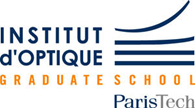|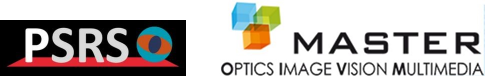|
|:--:|:--:|

# Digital Holography : numerical simulation and reconstruction
# Correction of part 1 of lab 1 - Discrete Fourier Transform and spectrum analysis


***


Two lab reports will be uploaded on Moodle : one at the end of the session and another one (completed) before the next session. 

+++ questions are optional.

***


In [11]:
# %matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

plt.rcParams["figure.figsize"] = (8,4) # choose the size of the figures : Width, height in inches.

# function that allows us to create axis from a vector of abscissa or ordinate
def ext_from_vect(f):
  delta = f[1] - f[0]
  return [f[0] - delta/2, f[-1] + delta/2]

## 1. 2D Discrete Fourier Transform (DFT)

### 1.1. Display of the images `sinus.png` and its spectrum

#### a. Load and display of the image `sinus.png` (`cv.imread(path,cv.IMREAD_GRAYSCALE)` + display of the labels of abscissa and ordinate axis 

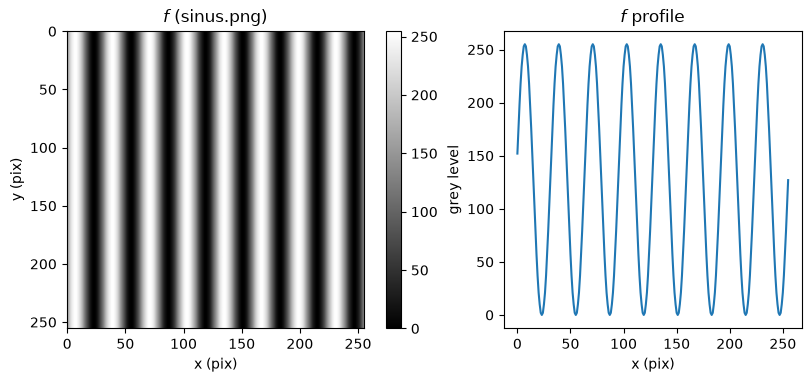

In [12]:
I=cv.imread('Lab1_Images/sinus.png',cv.IMREAD_GRAYSCALE) 
I=np.double(I)

H=I.shape[0]
W=I.shape[1]

plt.figure(layout='compressed')
plt.subplot(1,2,1)
plt.imshow(I,'gray')
plt.colorbar()
plt.title('$f$ (sinus.png)')
plt.xlabel('x (pix)') # puts a label for abscissa 
plt.ylabel('y (pix)') # puts a label for ordinates. Note it is important to put the axis units

plt.subplot(1,2,2)
plt.plot(I[1,:])
plt.title('$f$ profile')
plt.xlabel('x (pix)') # puts a label for abscissa 
plt.ylabel('grey level') # puts a label for ordinates. Note it is important to put the axis units

plt.show()

Comments : This image is a 2D signal that is invariant to translation in the y direction. Its Fourier transform along the y
direction has only one frequency, which is the zero frequency. The amplitude of this zero frequency varies
along the x direction. It is a sinusoidal function.

#### b. Computation of the spectrum 

In [13]:
FFT_I=np.fft.fft2(I) # computes the complex spectrum of I

#### c. Compute and display its phase and its modulus (angle, abs) 

By default the origin of the frequencies axis is on the left top corner and we visualize frequencies: $0 \leq \mu_x < 1$, $0 \leq \mu_y <1$). We have to center the origin using fftshift in order to visualize $-1/2 \leq \mu_x < 1/2$, $-1/2 \leq \mu_y < 1/2$. 

Understand, comment and use the following code (FFTimg contains the 2D DFT of the image):

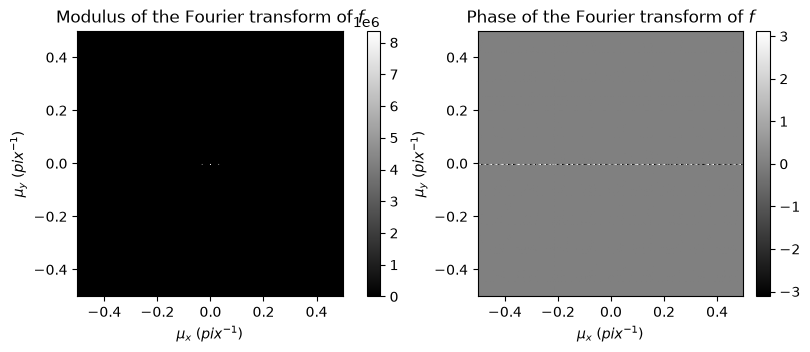

In [14]:
DISPLAY_FFT_I=np.fft.fftshift(FFT_I) # Shift of the spectrum FFTimg ( see lecture)
MODULUS_DISPLAY_FFT_I=np.abs(DISPLAY_FFT_I) # computation of spectrum modulus
PHASE_DISPLAY_FFT_I=np.angle(DISPLAY_FFT_I) # computation of spectrum phase
plt.figure(layout='compressed')
plt.subplot(1,2,1)
mux=np.arange(-0.5,0.5,1/W)  # in pixel^-1
muy=np.arange(-0.5,0.5,1/H)  # in pixel^-1
extmux=ext_from_vect(mux);extmuy=ext_from_vect(muy)

plt.imshow(MODULUS_DISPLAY_FFT_I,extent=np.concatenate([extmux,extmuy]),cmap='gray');
plt.colorbar()
plt.title('Modulus of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($pix^{-1}$)')
plt.ylabel(r'$\mu_y$ ($pix^{-1}$)')

plt.subplot(1,2,2)
plt.imshow(PHASE_DISPLAY_FFT_I,extent=np.concatenate([extmux,extmuy]),cmap='gray');
plt.colorbar()
plt.title('Phase of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($pix^{-1}$)') 
plt.ylabel(r'$\mu_y$ ($pix^{-1}$)')

plt.show()

#### d. Considering that pixel width is 5 µm, here is the display of the modulus and the phase of the spectrum using axis with frequency units in $m^{-1}$. 

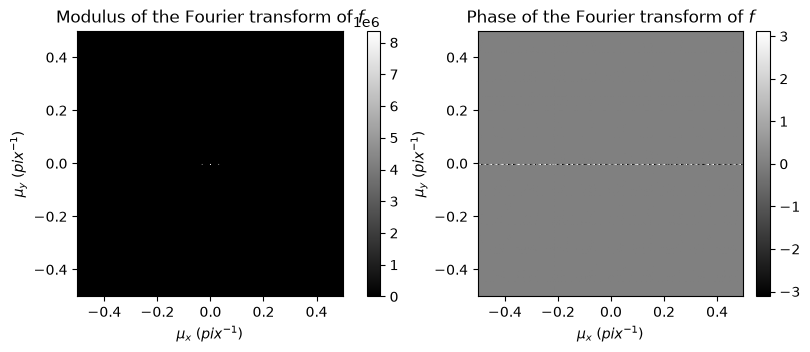

In [15]:
pp=5e-6
plt.figure(layout='compressed')
plt.subplot(1,2,1)
plt.imshow(MODULUS_DISPLAY_FFT_I,extent=np.concatenate([extmux,extmuy]),cmap='gray');
plt.colorbar()
plt.title('Modulus of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($pix^{-1}$)') 
plt.ylabel(r'$\mu_y$ ($pix^{-1}$)')

plt.subplot(1,2,2)
plt.imshow(PHASE_DISPLAY_FFT_I,extent=np.concatenate([extmux,extmuy]),cmap='gray');
plt.colorbar()
plt.title('Phase of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($pix^{-1}$)') 
plt.ylabel(r'$\mu_y$ ($pix^{-1}$)')

plt.show()

### 1.2. Spectrum analysis

#### a. Analyse the spectrum modulus (`np.abs`) and its phase (`np.angle`)

The image is a 2D signal that is invariant by translation in $y$ direction. Its Fourier transform along $y$ direction has only one frequency, it is the zero frequency. The amplitude of this zero frequency oscillate along the $x$ direction. It it a sine function.

The spectrum modulus shows a symmetry about the origin of the frequencies (because the signal/image is real): $ \lvert \tilde{f} (-\mu_x,-\mu_y) \rvert = \lvert \tilde{f} (\mu_x,\mu_y) \rvert$

The spectrum phase shows an anti-symmetry about the origin of the frequencies: $ \arg (\tilde{f} (-\mu_x,-\mu_y)) = \arg (\tilde{f} (\mu_x,\mu_y))$ 

The amplitude of the (0,0) frequency of the modulus spectrum is 8.36e6. It is the summation of all the grey-level of the image.

The amplitude of the (0.0312,0) frequency is 4.18e6. It is half the amplitude of the sine function multiplied by the number of pixels (see below).
It corresponds to a period of $T=1/0.0312=32 pix$. It is in agreement with the space domain where there are 8 periods on 256 pixels. 



In [16]:
I=cv.imread('Lab1_Images/sinus.png',cv.IMREAD_GRAYSCALE) # computation of the summation of all the gray levels of I
summation_GL_I=np.sum(I) 
summation_GL_I

np.uint64(8355584)

The phase of the spectrum is more difficult to interpret due to numerical noise. Only the 3 pixels of the modulus spectrum have non-negligible values. For the other pixels the phase value is not significant:

$f(m,n)=\sum\sum |\tilde{f}(p,q)|e^{j.\text{phase}(p,q)}e^{j2\pi (\frac{mp}{M}+\frac{nq}{N})}$

The phase of the ($0.0312 pix^{-1}$,0) frequency is equal to -1.37 rad in I. 

#### b. +++ The Fourier transform is invertible: test it by computing an inverse FT of the spectrum (`np.fft.ifft2`).

#### c. What happen in space domain if the magnitude of the zero frequency is put to zero in Fourier domain ?

In [17]:
FFT_I=np.fft.fft2(I) # computes the complex spectrum of I
FFT_I[0,0]=0
I_0=np.real(np.fft.ifft2(FFT_I))



Text(0, 0.5, 'grey level')

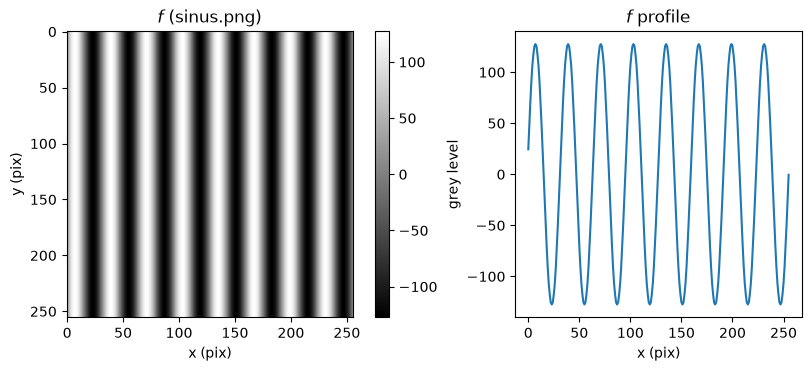

In [18]:
plt.figure(layout='compressed')
plt.subplot(1,2,1)
plt.imshow(I_0,'gray')
plt.colorbar()
plt.title('$f$ (sinus.png)')
plt.xlabel('x (pix)') # puts a label for abscissa 
plt.ylabel('y (pix)') # puts a label for ordinates. Note it is important to put the axis units


plt.subplot(1,2,2)
plt.plot(I_0[1,:])
plt.title('$f$ profile')
plt.xlabel('x (pix)') # puts a label for abscissa 
plt.ylabel('grey level') # puts a label for ordinates. Note it is important to put the axis units

Comments : the display of the image has not changed, but the colorbar (Look Up Table) has changed. The mean value of the image is now equal to zero.

#### d. What happen if all the values of the spectrum phase are put to zero before inverse FT ?

We know that $\tilde{f}(p,q)= |\tilde{f}(p,q)|e^{j.\text{phase}(p,q)}$

if for all pixels $(p,q)$, $\text{phase}(p,q)=0$ 

then 
$\tilde{f}(p,q)= |\tilde{f}(p,q)|$


Text(0, 0.5, 'grey level')

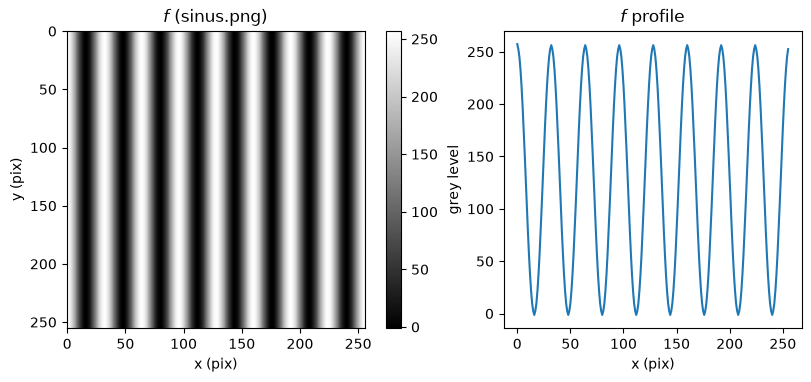

In [19]:
FFT_I=np.fft.fft2(I) 
I_1=np.real(np.fft.ifft2(np.abs(FFT_I)))
plt.figure(layout='compressed')
plt.subplot(1,2,1)
plt.imshow(I_1,'gray')
plt.colorbar()
plt.title('$f$ (sinus.png)')
plt.xlabel('x (pix)') # puts a label for abscissa 
plt.ylabel('y (pix)') # puts a label for ordinates. Note it is important to put the axis units


plt.subplot(1,2,2)
plt.plot(I_1[1,:])
plt.title('$f$ profile')
plt.xlabel('x (pix)') # puts a label for abscissa 
plt.ylabel('grey level') # puts a label for ordinates. Note it is important to put the axis units

Text(0, 0.5, 'grey level')

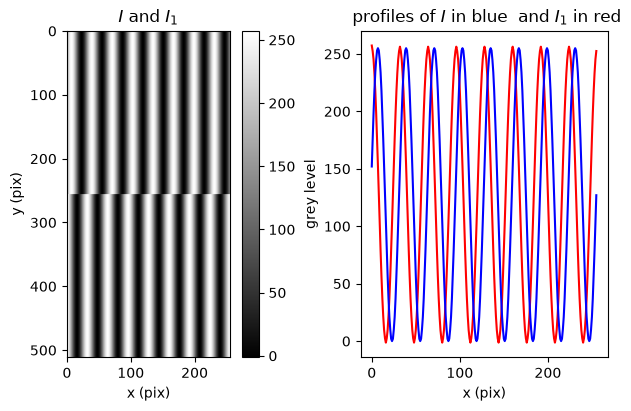

In [21]:
C = np.concatenate((I, I_1))
plt.figure(layout='compressed')
plt.subplot(1,2,1)
plt.imshow(C,'gray')
plt.colorbar()
plt.title('$I$ and $I_1$')
plt.xlabel('x (pix)') # puts a label for abscissa 
plt.ylabel('y (pix)') # puts a label for ordinates. Note it is important to put the axis units


plt.subplot(1,2,2)
plt.plot(I_1[1,:],'r',I[1,:],'b')
plt.title(' profiles of $I$ in blue  and $I_1$ in red')
plt.xlabel('x (pix)') # puts a label for abscissa 
plt.ylabel('grey level') # puts a label for ordinates. Note it is important to put the axis units

Comments: in this case (a single non-zero frequency is present in the spectrum) putting the phase of this frequency to zero in the Fourier Domain shifts the sine function in Space Domain. Its phase was 1.37 rad thus the shift is of $\frac{1.37}{2\pi}.T=7$ pixels.It is in agreement with the space domain where there are 7 pixels in between blue and red profiles. 